In [2]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

data_path = Path.cwd().parent / "data" / "customer_churn.csv"

df = pd.read_csv(data_path)

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

df.info()

Number of rows: 7043
Number of columns: 21
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessB

In [4]:
df.describe(include="all")

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,20.2,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,...,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


In [5]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Churn
No     5174
Yes    1869
Name: count, dtype: int64


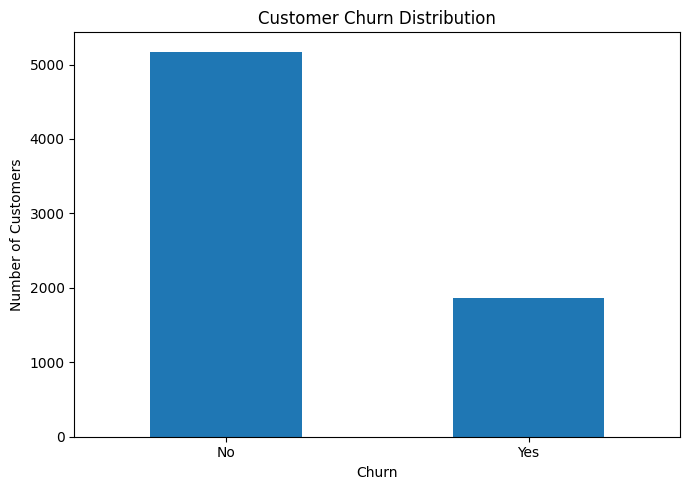

In [6]:
churn_counts = df["Churn"].value_counts()

print(churn_counts)

churn_counts.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [7]:
churn_percentage = (
    df["Churn"].value_counts(normalize=True) * 100
)

print(churn_percentage.round(2))

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


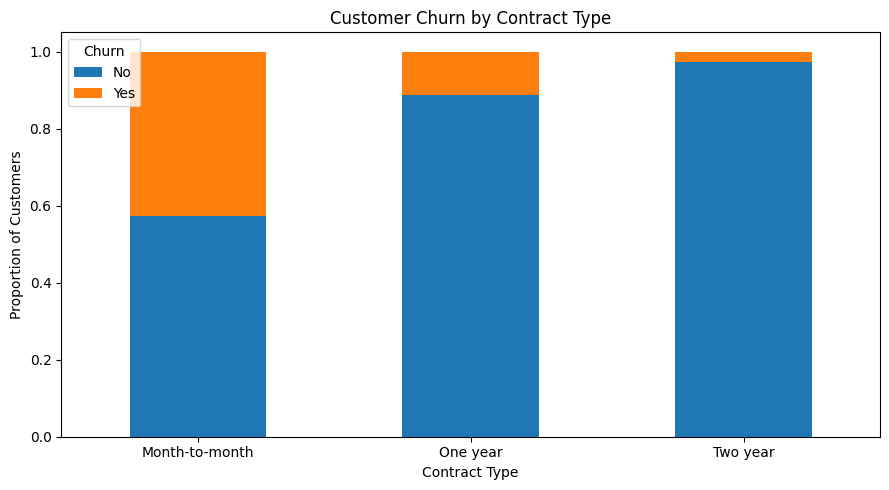

In [8]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
)

contract_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Proportion of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

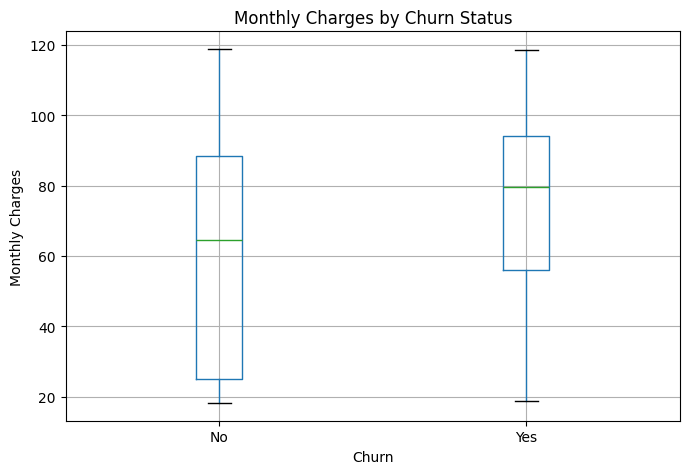

In [9]:
df.boxplot(
    column="MonthlyCharges",
    by="Churn",
    figsize=(7, 5)
)

plt.title("Monthly Charges by Churn Status")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()

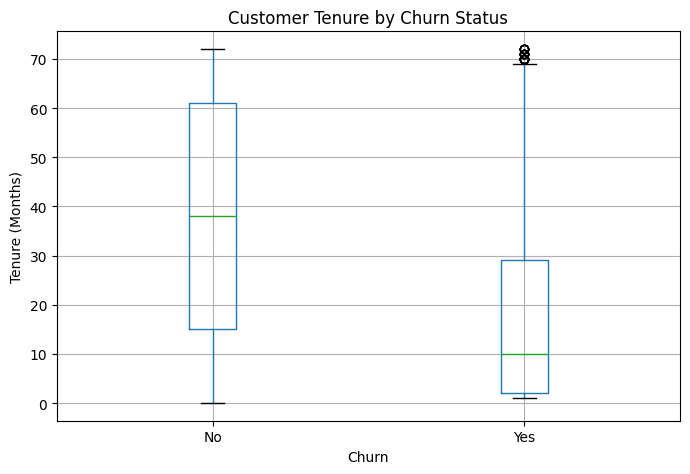

In [10]:
df.boxplot(
    column="tenure",
    by="Churn",
    figsize=(7, 5)
)

plt.title("Customer Tenure by Churn Status")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")
plt.tight_layout()
plt.show()

In [11]:
# Overall churn rate
print("Overall Churn Rate:")
print((df["Churn"].value_counts(normalize=True) * 100).round(2))

# Churn rate by contract type
print("\nChurn Rate by Contract Type:")
print(
    (df.groupby("Contract")["Churn"]
       .apply(lambda x: (x == "Yes").mean() * 100))
    .round(2)
)

# Average tenure by churn status
print("\nAverage Tenure by Churn Status:")
print(df.groupby("Churn")["tenure"].mean().round(2))

# Average monthly charges by churn status
print("\nAverage Monthly Charges by Churn Status:")
print(df.groupby("Churn")["MonthlyCharges"].mean().round(2))

Overall Churn Rate:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

Churn Rate by Contract Type:
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64

Average Tenure by Churn Status:
Churn
No     37.57
Yes    17.98
Name: tenure, dtype: float64

Average Monthly Charges by Churn Status:
Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64


## Exploratory Data Analysis — Key Findings

### 1. Customer Churn Distribution
- Approximately 26.54% of customers churned, while 73.46% remained.
- The dataset is imbalanced, with churned customers representing the smaller class.
- This makes metrics such as precision, recall, F1-score, and ROC-AUC useful alongside accuracy.

### 2. Churn by Contract Type
- Customers with month-to-month contracts had a churn rate of 42.71%, compared with 11.27% for one-year contracts and 2.83% for two-year contracts.
- Month-to-month contracts had the highest observed churn rate.
- Contract type appears to be associated with customer churn, although the analysis does not establish causation.

### 3. Customer Tenure
- Customers who churned had an average tenure of 17.98 months, compared with 37.57 months for customers who stayed.
- Customers who churned had substantially shorter average tenure, suggesting an association between lower tenure and churn.

### 4. Monthly Charges
- Customers who churned had average monthly charges of $74.44, compared with $61.27 for customers who stayed.
- Customers who churned tended to have higher monthly charges on average, suggesting a positive association between monthly charges and churn.

### 5. Overall Conclusion
- The exploratory analysis identified associations between customer churn and contract type, customer tenure, and monthly charges.
- Customers with month-to-month contracts, shorter tenure, and higher monthly charges may represent important segments for further churn analysis.
- These findings provide useful context for building and evaluating machine learning models that predict customer churn.